# Experiment 2: The eight queens problem
Aniruddh Vijayvargia (500125613), Batch D. Lab Manual, Chapter 3.

Generate-and-test over permutations against backtracking with pruning,
for n = 4 to 10. Timings are from one run on an AMD Ryzen 7 5800HS laptop.

In [1]:
import json, os, platform, time
from itertools import permutations
import matplotlib
import matplotlib.pyplot as plt

os.makedirs("figs", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10})
R = {"versions": {"python": platform.python_version(), "matplotlib": matplotlib.__version__},
     "cpu": platform.processor()}
print(R)

{'versions': {'python': '3.11.9', 'matplotlib': '3.11.2'}, 'cpu': 'AMD64 Family 25 Model 80 Stepping 0, AuthenticAMD'}


In [2]:
def conflicts(board):
    """board[c] = row of the queen in column c. Count attacking pairs."""
    n, bad = len(board), 0
    for i in range(n):
        for j in range(i + 1, n):
            if board[i] == board[j] or abs(board[i] - board[j]) == abs(i - j):
                bad += 1
    return bad

def generate_and_test(n):
    """Every permutation already has one queen per row and column; test diagonals only."""
    return [p for p in permutations(range(n)) if conflicts(p) == 0]

In [3]:
def is_safe(board, col, row):
    """Can a queen sit at (row, col) given columns 0..col-1 are filled?"""
    for c in range(col):
        if board[c] == row or abs(board[c] - row) == abs(c - col):
            return False
    return True

def backtrack(n):
    sols, nodes = [], [0]
    def place(board, col):
        if col == n:
            sols.append(tuple(board)); return
        for row in range(n):
            nodes[0] += 1                      # every (col, row) tried is one node
            if is_safe(board, col, row):
                board[col] = row               # place
                place(board, col + 1)
                board[col] = -1                # undo before the next sibling
    place([-1] * n, 0)
    return sols, nodes[0]

sols8, nodes8 = backtrack(8)
gt8 = generate_and_test(8)
print(len(sols8), "solutions by backtracking,", nodes8, "nodes;", len(gt8), "by generate-and-test")
print("first solution:", sols8[0])
assert sorted(sols8) == sorted(gt8)

92 solutions by backtracking, 15720 nodes; 92 by generate-and-test
first solution: (0, 4, 7, 5, 2, 6, 1, 3)


## Fundamental solutions under the 8 symmetries of the square

In [4]:
def symmetries(b):
    n = len(b)
    pts = [(c, r) for c, r in enumerate(b)]
    out = set()
    for k in range(8):
        q = []
        for c, r in pts:
            for _ in range(k % 4):
                c, r = r, n - 1 - c            # rotate 90 degrees
            if k >= 4:
                c = n - 1 - c                  # reflect
            q.append((c, r))
        out.add(tuple(r for c, r in sorted(q)))
    return out

classes = {min(symmetries(s)) for s in sols8}
n_images = sorted(len(symmetries(min(symmetries(s)))) for s in classes)
R["fundamental"] = {"count": len(classes), "images_per_class": n_images}
print(R["fundamental"])

{'count': 12, 'images_per_class': [4, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8]}


## Scaling, n = 4 to 10

In [5]:
rows = []
for n in range(4, 11):
    t0 = time.perf_counter(); s, nd = backtrack(n); tb = time.perf_counter() - t0
    t0 = time.perf_counter(); g = generate_and_test(n); tg = time.perf_counter() - t0
    rows.append({"n": n, "solutions": len(s), "solutions_gt": len(g), "nodes": nd,
                 "t_backtrack": tb, "t_generate": tg})
    print(f"{n:>3} {len(s):>6} {len(g):>6} {nd:>9} {tb:9.4f}s {tg:9.4f}s")
R["table"] = rows
R["same_counts"] = all(r["solutions"] == r["solutions_gt"] for r in rows)
R["first_solution_n8"] = list(sols8[0]); R["nodes_n8"] = nodes8

  4      2      2        60    0.0000s    0.0001s
  5     10     10       220    0.0001s    0.0003s
  6      4      4       894    0.0003s    0.0017s
  7     40     40      3584    0.0014s    0.0209s


  8     92     92     15720    0.0077s    0.1956s


  9    352    352     72378    0.0493s    2.0064s


 10    724    724    348150    0.2282s   26.9901s


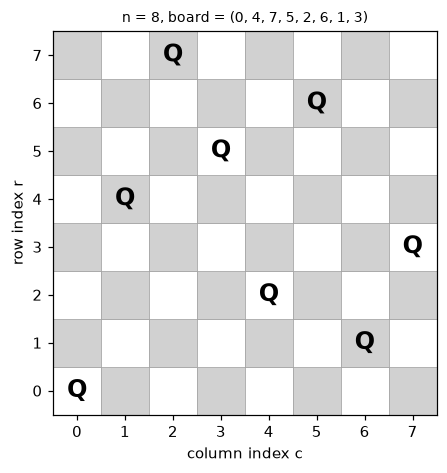

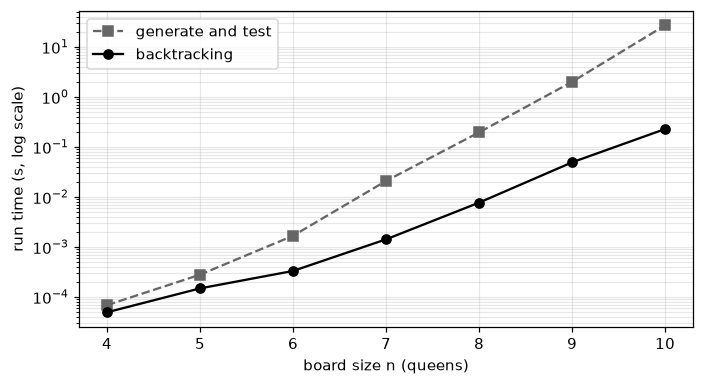

In [6]:
n = 8
fig1 = plt.figure(figsize=(4.4, 4.4)); ax = fig1.gca()
for r in range(n):
    for c in range(n):
        ax.add_patch(plt.Rectangle((c, r), 1, 1, color="0.82" if (r + c) % 2 else "w", ec="0.6", lw=0.4))
for c, r in enumerate(sols8[0]):
    ax.text(c + 0.5, r + 0.5, "Q", ha="center", va="center", fontsize=16, fontweight="bold")
ax.set_xlim(0, n); ax.set_ylim(0, n); ax.set_aspect("equal")
ax.set_xticks([i + 0.5 for i in range(n)], range(n)); ax.set_yticks([i + 0.5 for i in range(n)], range(n))
ax.set_xlabel("column index c"); ax.set_ylabel("row index r")
ax.set_title(f"n = 8, board = {sols8[0]}", fontsize=9)
fig1.tight_layout(); fig1.savefig("figs/fig2_1_board.png")

ns = [r["n"] for r in rows]
fig2 = plt.figure(figsize=(6.5, 3.6)); ax = fig2.gca()
ax.semilogy(ns, [r["t_generate"] for r in rows], "s--", color="0.4", label="generate and test")
ax.semilogy(ns, [r["t_backtrack"] for r in rows], "o-", color="k", label="backtracking")
ax.set_xlabel("board size n (queens)"); ax.set_ylabel("run time (s, log scale)")
ax.legend(); ax.grid(alpha=0.3, which="both")
fig2.tight_layout(); fig2.savefig("figs/fig2_2_runtime.png")

In [7]:
with open("results.json", "w") as fh:
    json.dump(R, fh, indent=2)
print("saved results.json; same solution counts for every n:", R["same_counts"])

saved results.json; same solution counts for every n: True
